## Optional stretch: The "Messy" Storm Analysis

**Goal:** Apply method chaining to clean a dataset with missing values, inconsistent strings, and mixed types.

### The Scenario
You have received a raw data dump of storm sightings from an amateur weather network. The data is dirty:
* Column names are inconsistent.
* `Wind_Speed` contains units (e.g., "100 mph") and needs to be numeric.
* `Pressure` has missing values (`NaN`).
* `Date` is a string that needs parsing.

**Your Mission:** 
Create a **single method chain** that cleans this data and produces a summary table showing the average wind speed per year.

In [1]:
# Data Cleaning Exercise: Storm Data Analysis
# In this exercise, we will work with a "dirty" dataset containing information about various storms. The dataset includes inconsistencies in date formats, wind speed representations, and missing values. Your task is to clean the data and prepare it for analysis.

import pandas as pd
import numpy as np

# 1. Setup the "Dirty" Data
raw_storm_data = pd.DataFrame({
    'Storm Name': ['Alpha', 'Beta', 'GAMMA', 'Delta', 'Epsilon', 'Zeta', 'Eta'],
    'Date Observed': ['2020-05-15', '2020/06/01', '2021-08-10', '2021-09-12', '2020-11-05', '2022-01-15', '2022-03-20'],
    'Wind_Speed': ['120 mph', '60 mph', '110', '130 mph', '50', '140 mph', 'Unknown'],
    'Pressure (mb)': [950, 990, np.nan, 940, 1000, 930, 980],
    'Damage_Cost': ['$5M', '$0.5M', '$10M', '$20M', '$0.1M', '$15M', '$2M']
})

print("The Dirty Data:")
display(raw_storm_data)

The Dirty Data:


,Storm Name,Date Observed,Wind_Speed,Pressure (mb),Damage_Cost
0,Alpha,2020-05-15,120 mph,950.0,$5M
1,Beta,2020/06/01,60 mph,990.0,$0.5M
2,GAMMA,2021-08-10,110,NaN,$10M
3,Delta,2021-09-12,130 mph,940.0,$20M
4,Epsilon,2020-11-05,50,1000.0,$0.1M
5,Zeta,2022-01-15,140 mph,930.0,$15M
6,Eta,2022-03-20,Unknown,980.0,$2M


## The Challenge
Write a pipeline `clean_storm_summary` that performs the following steps:

1.  **Rename columns:** Make them lowercase and replace spaces with underscores (e.g., `Storm Name` -> `storm_name`).
2.  **Clean Strings:** Ensure all storm names are Title Case (e.g., "Gamma", not "GAMMA").
3.  **Handle Missing/Bad Data:** 
    * Coerce `wind_speed` to numeric (remove " mph" and handle "Unknown" as NaN).
    * Drop rows where `wind_speed` is NaN.
4.  **Feature Engineering:** 
    * Extract the `year` from `date_observed`.
    * Convert `damage_cost` to a float (remove "$" and "M", multiply by 1,000,000).
5.  **Aggregation:** 
    * Group by `year`.
    * Calculate the **mean wind_speed** and **total damage_cost**.

---

### Some useful hints to assist you here:

**For Step 1: Renaming Columns**
- Which pandas method allows you to rename columns using a function?
- How can you chain multiple string transformations (lowercase, replace spaces, remove special characters)?

**For Step 2: Cleaning Storm Names**
- Which method allows you to update multiple columns in a single chain?
- Is there a string method that converts text to Title Case?

**For Step 3: Handling Wind Speed**
- How would you extract just the numeric part from "120 mph"?
- What pandas function converts strings to numbers AND handles conversion errors gracefully?
- Which method removes rows with missing values in a specific column?

**For Step 4: Extracting Year**
- How do you convert a string date into a datetime object?
- Once converted to datetime, how do you extract just the year component?

**For Step 5: Cleaning Damage Cost**
- How do you remove multiple different characters ("$", "M") from a string column?
- After removing characters, how do you convert the result to a numeric type?

**For Step 6: Aggregation**
- Which method splits data into groups based on a column value?
- What method applies multiple functions (mean, sum) across different columns in one step?

**Critical Order Question:**
- Why must you rename columns before you start working with them in `.assign()`?
- Why must you remove bad data (`.dropna()`) before aggregation?

---

### Some more hints if you got stuck
* To replace string characters: `.str.replace('old', 'new')`
* To convert to numeric, forcing errors to NaN: `pd.to_numeric(col, errors='coerce')`
* To extract year from a string date: `pd.to_datetime(col).dt.year`

In [ ]:
# YOUR CODE HERE

# clean_storm_summary = (
#     raw_storm_data
#     .rename(...)
#     .assign(...)
#     ...
# )

In [ ]:
# INSTRUCTOR SOLUTION (Hidden)

clean_storm_summary = (
    raw_storm_data
    # 1. Rename
    .rename(columns=lambda x: x.strip().lower().replace(' ', '_').replace('(mb)', '').strip('_'))
    
    # 2. Assign & Clean
    .assign(
        storm_name = lambda x: x['storm_name'].str.title(),
        # Clean wind_speed: remove ' mph', coerce errors ('Unknown') to NaN
        wind_speed = lambda x: pd.to_numeric(x['wind_speed'].str.replace(' mph', ''), errors='coerce'),
        # Clean damage: remove symbols, convert to float
        damage_cost = lambda x: x['damage_cost'].str.replace('$', '').str.replace('M', '').astype(float) * 1_000_000,
        # Extract Year
        year = lambda x: pd.to_datetime(x['date_observed']).dt.year
    )
    
    # 3. Filter bad data
    .dropna(subset=['wind_speed'])
    
    # 4. Aggregate
    .groupby('year')
    .agg(
        avg_wind_speed=('wind_speed', 'mean'),
        total_damage=('damage_cost', 'sum')
    )
)

clean_storm_summary

## The Challenge: The HR "Training Paradox"  - Data visualisation

**The Scenario:** 
The HR department is confused. They ran a simple correlation and found that **Employees who attend MORE training have LOWER performance scores**. They are considering cancelling the training budget.

**Your Hypothesis:** 
You suspect there is a confounding variable: **Seniority**. Junior staff attend more training but naturally have lower output than Seniors. Seniors attend less training but produce more.

**Task:**
1.  Plot a simple `regplot` of `Training_Hours` vs `Performance` (Observe the negative trend).
2.  Plot an `lmplot` of the same variables, but map `hue` to `Seniority`.
3.  **Conclusion:** Does training actually help within each group?

---

### Some hints

**For the Misleading Plot:**
- Which Seaborn function creates a scatter plot with a regression line?
- What happens to the overall trend when you mix two groups with opposite patterns?
- Can you spot the confounding variable just by looking at the global trend?

**For the Truth-Revealing Plot:**
- Which Seaborn function allows you to split a plot by a categorical variable using `hue`?
- What do the separate regression lines (one for Junior, one for Senior) reveal that the global line hid?
- How does adding colour coding change your interpretation of the relationship?

**Interpretation Questions:**
- Why does the global trend show a negative relationship when the real effect is positive?
- What role does Seniority play in both training hours AND performance?
- How can Simpson's Paradox lead to poor business decisions if you don't investigate further?
- What other confounding variables might exist in real HR datasets?


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Setup the "Paradox" Data
np.random.seed(101)
n = 200

# Juniors: High Training, Lower Base Performance
juniors = pd.DataFrame({
    'Training_Hours': np.random.normal(40, 5, 100),
    'Base_Skill': np.random.normal(50, 5, 100),
    'Seniority': 'Junior'
})
# Seniors: Low Training, Higher Base Performance
seniors = pd.DataFrame({
    'Training_Hours': np.random.normal(10, 5, 100),
    'Base_Skill': np.random.normal(80, 5, 100),
    'Seniority': 'Senior'
})

hr_data = pd.concat([juniors, seniors])

# Performance increases with Training, but Seniors start much higher
hr_data['Performance'] = hr_data['Base_Skill'] + (hr_data['Training_Hours'] * 0.5) + np.random.normal(0, 2, 200)

print("HR Data Sample:")
display(hr_data.sample(5))

HR Data Sample:


,Training_Hours,Base_Skill,Seniority,Performance
34,10.927395,82.720796,Senior,86.617296
2,44.539847,43.073107,Junior,67.725640
19,43.417544,46.455231,Junior,70.665910
73,13.328573,72.834347,Senior,79.787871
81,37.529523,41.835380,Junior,61.185803


In [ ]:
# YOUR CODE HERE

# 1. The Misleading Plot (Simple Regression)
# sns.regplot(...)

# 2. The Truth (Multivariate Regression with Hue)
# sns.lmplot(...)

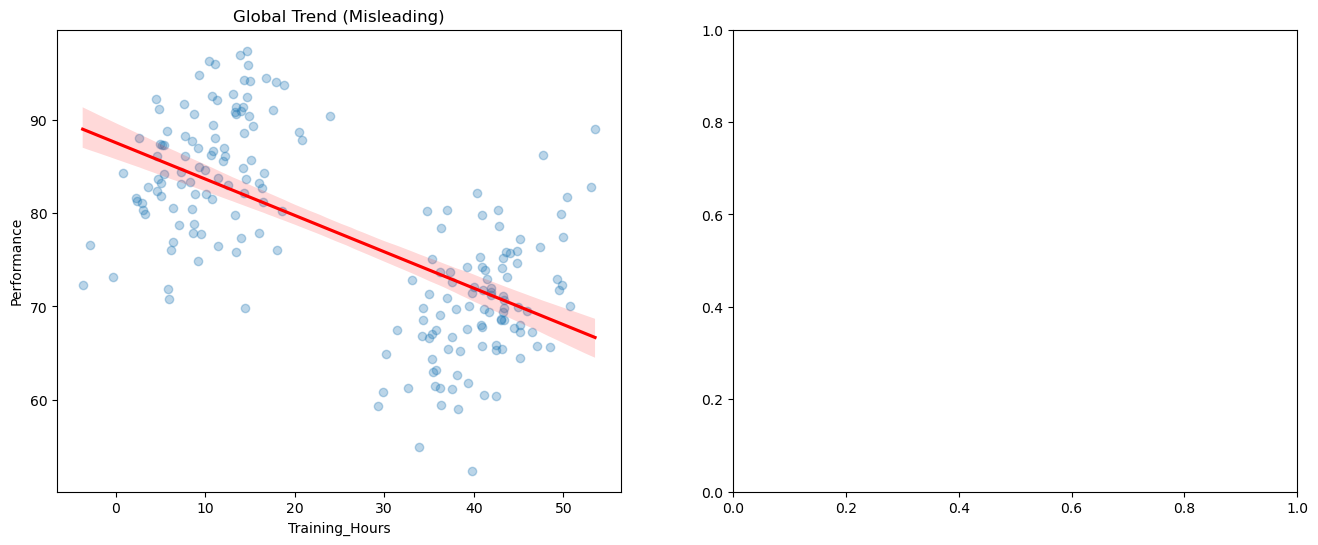

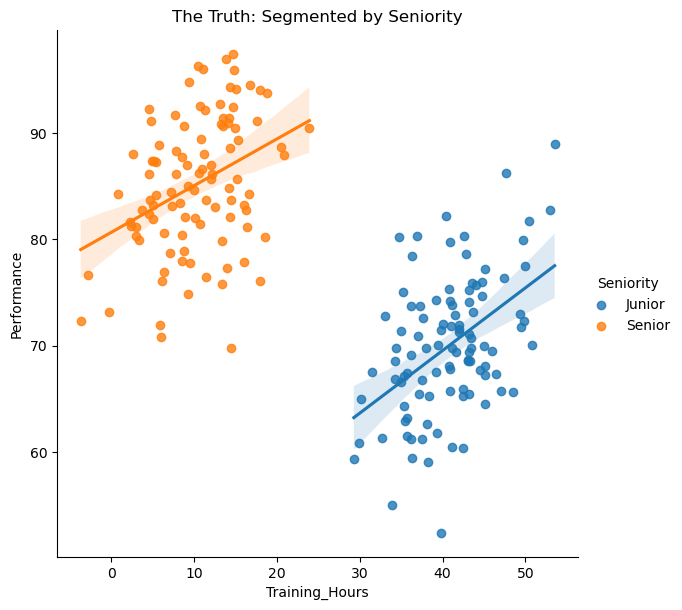

In [ ]:
# INSTRUCTOR SOLUTION (Hidden)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: The Lie
sns.regplot(data=hr_data, x='Training_Hours', y='Performance', ax=ax1, scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
ax1.set_title("Global Trend (Misleading)")

# Plot 2: The Truth (Using lmplot would create a new figure, so we use scatterplot+lines or just lmplot separate)
# For side-by-side in matplotlib, we can manually do it, or just let them run lmplot below.
# Here is the lmplot code:
sns.lmplot(data=hr_data, x='Training_Hours', y='Performance', hue='Seniority', height=6)
plt.title("The Truth: Segmented by Seniority")
plt.show()

### Challenge: The Supply Chain "Risk" (Distributions)

**The Scenario:** 
You manage three delivery hubs. The manager reports that all three have the same **Average Delivery Time** (48 hours), so they are performing equally.

**Your Hypothesis:** 
Averages hide risk. You suspect one hub is reliable, while another is chaotic (sometimes fast, sometimes very late).

**Task:**
1.  Use `sns.boxplot` or `sns.violinplot` to compare the *shape* of `Delivery_Hours` for each `Hub`.
2.  **Bonus:** Overlay a `sns.stripplot` or `sns.swarmplot` to see the raw data points.
3.  **Question:** Which Hub is the most "Risky" (highest variance/longest tail)?

---

### Guiding Questions

**Choosing Your Visualization:**
- What is the difference between a box plot (shows 5-point summary) and a violin plot (shows full distribution shape)?
- Which one would better reveal if one hub has extreme outliers?
- Why is showing the raw data points (with `swarmplot` or `stripplot`) useful alongside the summary?

**Interpreting the Plots:**
- Look at the width of each hub's box/violin: What does a **tall box** versus a **short box** tell you?
- What does it mean if a hub's distribution has a **long tail** extending in one direction?
- Which hub's plot looks like a tight cluster? Which one is spread out?

**Risk Analysis Questions:**
- If all three hubs have the same average (48 hours), why would you still prefer one over the others?
- What could go wrong if you chose Hub B (chaotic) for a critical delivery?
- How would you explain the risk difference to a manager who only looks at averages?
- What business metrics (customer satisfaction, SLAs) might be affected by variance, not just mean?


In [ ]:
# Setup Supply Chain Data
np.random.seed(42)

# Hub A: Consistent (Normal distribution, small std dev)
hub_a = np.random.normal(48, 2, 100)

# Hub B: Chaotic (Normal distribution, HUGE std dev)
hub_b = np.random.normal(48, 15, 100)

# Hub C: The "Long Tail" (Exponential/Skewed)
hub_c = np.random.exponential(10, 100) + 38 # Shifted to match mean approx

logistics_df = pd.DataFrame({
    'Delivery_Hours': np.concatenate([hub_a, hub_b, hub_c]),
    'Hub': ['Hub A']*100 + ['Hub B']*100 + ['Hub C']*100
})

print("Logistics Data Loaded.")

Logistics Data Loaded.


In [ ]:
# YOUR CODE HERE

# plt.figure(figsize=(10,6))
# sns.violinplot(...)
# sns.swarmplot(...)

/var/folders/q9/wc4_0qyx4xn17dfwb9vk_4140000gq/T/ipykernel_10701/868196258.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=logistics_df, x='Hub', y='Delivery_Hours', inner=None, palette='pastel')


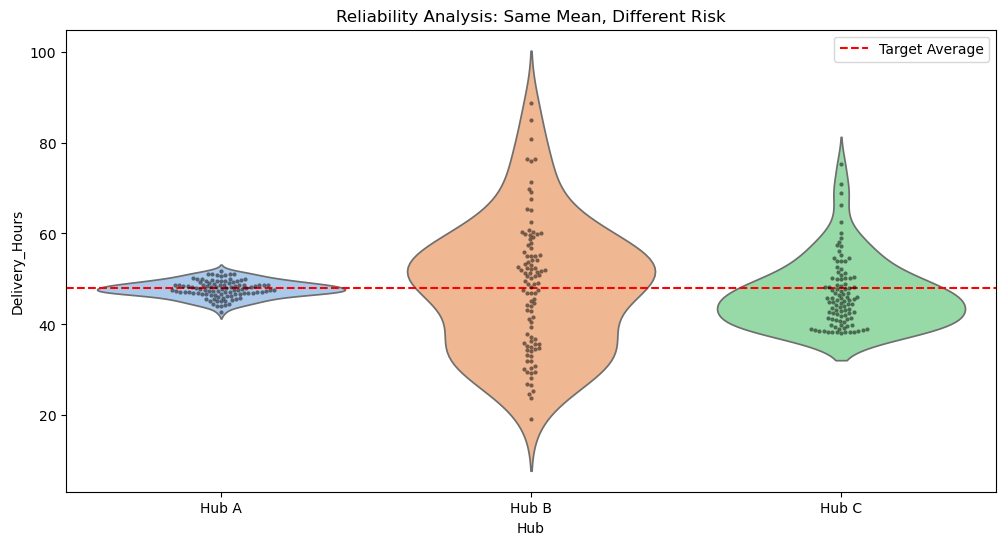

In [ ]:
# INSTRUCTOR SOLUTION

plt.figure(figsize=(12, 6))

# Violin plot shows the density (fatness) of the data
sns.violinplot(data=logistics_df, x='Hub', y='Delivery_Hours', inner=None, palette='pastel')

# Swarm plot shows every single dot (great for spotting outliers)
sns.swarmplot(data=logistics_df, x='Hub', y='Delivery_Hours', color='k', alpha=0.5, size=3)

plt.title("Reliability Analysis: Same Mean, Different Risk")
plt.axhline(48, color='r', linestyle='--', label='Target Average')
plt.legend()
plt.show()

### Interpretation Guide
* **Hub A:** The "Safe Bet". Tight cluster around the mean.
* **Hub B:** The "Wildcard". Deliveries can be super early or super late.
* **Hub C:** The "Risky" one. Note the long tail stretching upwards—these are the customers who will complain.